# 03MIAR - Algoritmos de optimización
## Actividad guiada 3

*Lucas Tamara Trejo*

Repositorio con el notebook y el PDF: https://github.com/lucastamaraucv/AG3


## Presentación

Profesor:
- Grupos A2, A3, B1, B2: David Álvarez Robles (dalvarezr@professor.universidadviu.com)

## Objetivos
- Comprender el uso de librerías de simulación del problema del agente viajero en Python
- Implementar y visualizar algoritmos de búsqueda basados en metaheurísticas
- Algoritmo de búsqueda aleatoria
- Algoritmo de búsqueda local
- Algoritmo Simulated Annealing

## Librerías y simulación del problema del agente viajero en Python
- Uso de librería tsplib95
- Visualización de datos

In [1]:
!pip install tsplib95
import tsplib95
import random
from math import e
import math
import copy
import urllib.request

Defaulting to user installation because normal site-packages is not writeable


In [2]:
# Descargamos el fichero de datos (Matriz de distancias)
file = "swiss42.tsp" ;
urllib.request.urlretrieve("https://raw.githubusercontent.com/mastqe/tsplib/refs/heads/master/swiss42.tsp", file  )

#urllib.request.urlretrieve("https://raw.githubusercontent.com/mastqe/tsplib/refs/heads/master/swiss42.tsp", file + '.gz')
#!gzip -d swiss42.tsp.gz     #Descomprimir el fichero de datos

#Coordendas 51-city problem (Christofides/Eilon)
#file = "eil51.tsp" ; urllib.request.urlretrieve("http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/eil51.tsp.gz", file)

#Coordenadas - 48 capitals of the US (Padberg/Rinaldi)
#file = "att48.tsp" ; urllib.request.urlretrieve("http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/att48.tsp.gz", file)


#http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95
#Documentacion :
  # http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp95.pdf
  # https://tsplib95.readthedocs.io/en/stable/pages/usage.html
  # https://tsplib95.readthedocs.io/en/v0.6.1/modules.html
  # https://pypi.org/project/tsplib95/

('swiss42.tsp', <http.client.HTTPMessage at 0x24d0e15d810>)

In [3]:
problema = tsplib95.load(file)
nodos = list(problema.get_nodes())
aristas = list(problema.get_edges())

print(problema) # Descripción estándar
print(nodos) # Nodos 0, 1, 2 ... 42
print(aristas) # Ver https://github.com/mastqe/tsplib/blob/master/swiss42.tsp

NAME: swiss42
COMMENT: 42 Staedte Schweiz (Fricker)
TYPE: TSP
DIMENSION: 42
EDGE_WEIGHT_TYPE: EXPLICIT
EDGE_WEIGHT_FORMAT: FULL_MATRIX
EDGE_WEIGHT_SECTION:
0 15 30 23 32 55 33 37 92 114 92 110 96 90 74 76 82 67 72 78 82 159 122 131 206 112 57 28 43 70 65 66 37 103 84 125 129 72 126 141 183 124
15 0 34 23 27 40 19 32 93 117 88 100 87 75 63 67 71 69 62 63 96 164 132 131 212 106 44 33 51 77 75 72 52 118 99 132 132 67 139 148 186 122
30 34 0 11 18 57 36 65 62 84 64 89 76 93 95 100 104 98 57 88 99 130 100 101 179 86 51 4 18 43 45 95 45 115 93 152 159 100 112 114 153 94
23 23 11 0 11 48 26 54 70 94 69 89 75 84 84 89 92 89 54 78 99 141 111 109 190 89 44 11 29 54 56 89 47 118 96 147 151 90 122 126 163 101
32 27 18 11 0 40 20 58 67 92 61 78 65 76 83 89 91 95 43 72 110 141 116 105 190 81 34 19 35 57 63 97 58 129 107 156 158 92 129 127 161 95
55 40 57 48 40 0 23 55 96 123 78 75 62 36 56 66 63 95 37 34 137 174 156 129 224 90 15 59 75 96 103 105 91 158 139 164 156 78 169 163 191 115
33 19 36 26 20 

23


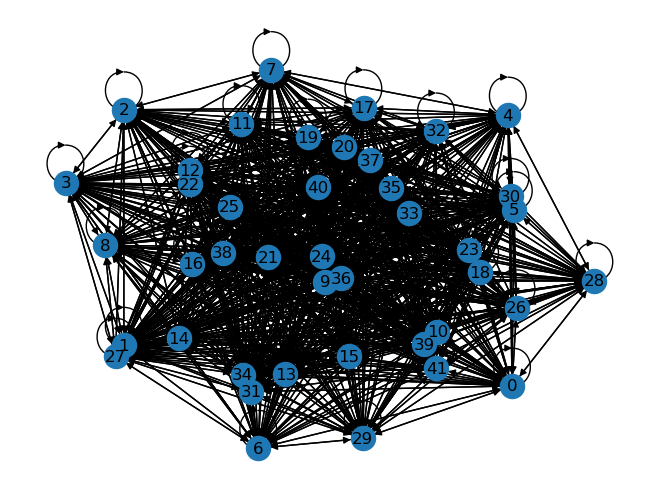

In [4]:
# Probamos algunas funciones del objeto problema, que ya nos vienen dadas

# Distancia entre nodos (ciudades)
distancia = problema.get_weight(3, 0)
print(distancia)

#Todas las funciones
#Documentación: https://tsplib95.readthedocs.io/en/v0.6.1/modules.html
#dir(problema)

import networkx as nx
import matplotlib.pyplot as plt
nx.draw(problema.get_graph(), with_labels=True, arrows=True)
plt.show()

In [5]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.manifold import MDS  # Multidimensional Scaling o Escalado Multidimensional

def plot_tsp_solution(distance_matrix, tsp_solution):
    """
    Dibuja el grafo de un TSP con las posiciones calculadas mediante MDS y muestra
    solo las aristas correspondientes a la solución del TSP.

    :param distance_matrix: np.ndarray, matriz de distancias entre nodos
    :param tsp_solution: list, lista de nodos en el orden de la solución del TSP
    """
    # Crear el grafo completo
    G = nx.Graph()
    num_nodes = len(distance_matrix)
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes):
            G.add_edge(i, j, weight=distance_matrix[i][j])

    # Usar MDS para calcular posiciones de los nodos
    mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42)
    positions = mds.fit_transform(distance_matrix)

    # Convertir las posiciones en un diccionario para networkx
    pos = {i: positions[i] for i in range(num_nodes)}

    # Crear un subgrafo con las aristas del camino TSP
    TSP_G = nx.Graph()
    for i in range(len(tsp_solution) - 1):
        u = tsp_solution[i]
        v = tsp_solution[i + 1]
        TSP_G.add_edge(u, v, weight=distance_matrix[u][v])

    # Dibujar el grafo
    plt.figure(figsize=(8, 6))

    # Dibujar nodos
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=500)

    # Dibujar las aristas del camino TSP
    nx.draw_networkx_edges(TSP_G, pos, edge_color='red', width=2)

    # Añadir etiquetas a los nodos y pesos de las aristas
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    edge_labels = nx.get_edge_attributes(TSP_G, 'weight')
    nx.draw_networkx_edge_labels(TSP_G, pos, edge_labels=edge_labels, font_size=8)

    plt.title("Grafo TSP con solución específica")
    plt.show()

## Funciones básicas para algoritmos de búsqueda

In [6]:
# Genera una solución aleatoria con comienzo en en el nodo 0
def crear_solucion(nodos):
    # Nodo inicial = 0
    solucion = [nodos[0]]
    # Para el resto de nodos, los recorremos e incluimos aleatoriamente en la solución cada uno de ellos
    for n in nodos[1:]:
        # Debemos quitar el nodo 0 y los ya incluidos en cada iteración
        solucion = solucion + [random.choice(list(set(nodos) - set({nodos[0]}) - set(solucion)))]
    return solucion


# Devuelve la distancia entre dos nodos aprovechando la función get_weight() de tsplib95
def distancia(a,b, problema):
    return problema.get_weight(a,b)


# Devuelve la distancia total de una trayectoria/solución
def distancia_total(solucion, problema):
    distancia_total = 0
    # Para cada nodo de la solución calculamos su distancia a siguiente nodo
    for i in range(len(solucion)-1):
        distancia_total += distancia(solucion[i] ,solucion[i+1] ,  problema)
    # Devolvemos la distancia total más la distancia del último nodo al primero para cerrar viaje
    return distancia_total + distancia(solucion[len(solucion)-1] ,solucion[0], problema)


solucion = crear_solucion(nodos)
print(solucion)
print(distancia_total(solucion, problema))

[0, 21, 27, 38, 13, 2, 36, 16, 34, 25, 15, 11, 32, 30, 3, 31, 20, 10, 6, 41, 4, 35, 7, 22, 8, 40, 23, 9, 5, 29, 28, 24, 14, 19, 37, 39, 12, 17, 33, 26, 18, 1]
4759


## Búsqueda aleatoria - TSP
- El algoritmo inicializa soluciones al azar y se queda con la mejor que encuentre
- Se realizan N iteraciones y nos quedamos con la mejor
- Todo es azar, sin que garanticemos solución óptima

Solución: [0, 20, 31, 5, 18, 19, 22, 38, 29, 7, 35, 34, 17, 15, 14, 36, 25, 10, 9, 41, 1, 4, 13, 37, 3, 32, 23, 39, 33, 8, 11, 12, 2, 21, 24, 6, 16, 28, 27, 26, 40, 30]
Distancia: 3759


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


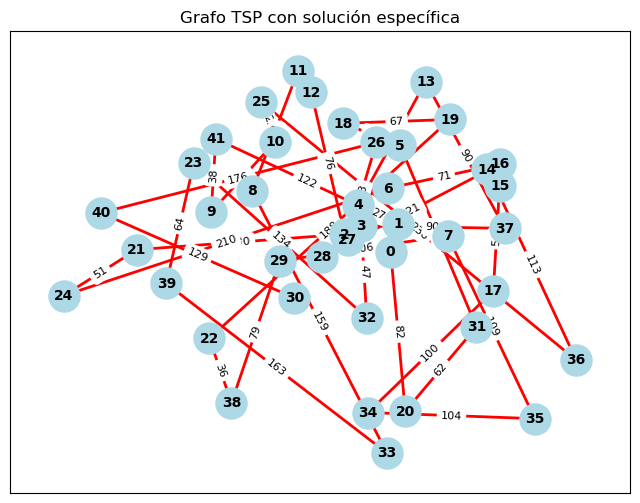

In [7]:
def busqueda_aleatoria(problema, iteraciones):
    # Obtenemos listado de nodos del problema
    nodos = list(problema.get_nodes())

    mejor_solucion = []
    mejor_distancia_total = float("inf")

    for i in range(iteraciones):
        # Generamos solución aleatoria
        solucion = crear_solucion(nodos)
        # Calculamos distancia total de la solución
        distancia = distancia_total(solucion, problema)
        if (distancia < mejor_distancia_total):
            mejor_solucion = solucion
            mejor_distancia_total = distancia

    return mejor_solucion, mejor_distancia_total

iteraciones = 5000
mejor_solucion, mejor_distancia_total = busqueda_aleatoria(problema, iteraciones)

print(f"Solución: {mejor_solucion}")
print(f"Distancia: {mejor_distancia_total}")

plot_tsp_solution(problema.edge_weights, mejor_solucion)



## Búsqueda local - TSP
- El algoritmo se va quedando con vecinos (operadores de vecindad) para intentar converger a mejores soluciones
- Se realizan N iteraciones y nos quedamos con la mejor

In [8]:
# Función que a partir de una solución genera la vecina óptima (es decir, la mejor vecina de todas las que existen)
def genera_mejor_vecina(solucion):
    # Generador de soluciones vecinas: 2-opt (intercambiar 2 nodos) Si hay N nodos se generan (N-1)x(N-2)/2 soluciones en el bucle
    # Se puede modificar para aplicar otros generadores distintos que 2-opt como inversión, barajado...
    #print(solucion)

    mejor_solucion = []
    mejor_distancia = float("inf")

    #Recorremos todos los nodos en bucle doble para evaluar todos los intercambios 2-opt
    for i in range(1,len(solucion)-1):
        for j in range(i+1, len(solucion)):
            # Generamos nueva solución vecina (0, 1, 2, 3, i, ..., j, ..., 41) -> (0, 1, 2, 3, j, ..., i, ..., 41)
            vecina = solucion[:i] + [solucion[j]] + solucion[i+1:j] + [solucion[i]] + solucion[j+1:]

            # Se evalua la nueva solución
            distancia_vecina = distancia_total(vecina, problema)

            # Si es la mejor solución, la almacenamos
            if (distancia_vecina <= mejor_distancia):
                mejor_distancia = distancia_vecina
                mejor_solucion = vecina

    # Devolvemos mejor vecina
    return mejor_solucion


solucion = crear_solucion(nodos)
print(f"Distancia Solucion Incial: {distancia_total(solucion, problema)}")

nueva_solucion = genera_mejor_vecina(solucion)
print(f"Distancia Mejor Solucion Local: {distancia_total(nueva_solucion, problema)}")

Distancia Solucion Incial: 5046
Distancia Mejor Solucion Local: 4279


En la iteracion 30 la mejor solución encontrada es: [0, 3, 8, 41, 23, 9, 39, 21, 24, 40, 10, 25, 11, 12, 18, 28, 30, 34, 32, 2, 27, 31, 17, 1, 4, 6, 5, 26, 29, 22, 38, 33, 20, 13, 19, 14, 16, 15, 7, 37, 36, 35]
Distancia: 1966


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


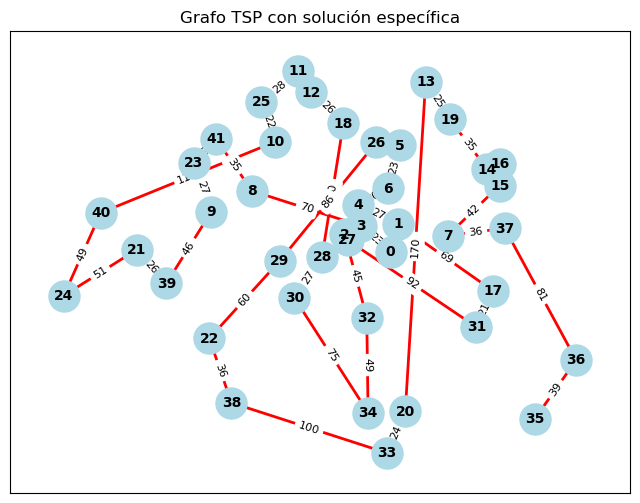

In [9]:
# En este caso, la búsqueda se ejecuta sin criterio de parada, se para cuando no es posible mejorar.
# Aquí iremos recorriendo las mejores vecinas para ir construyendo trayectoria
def busqueda_local(problema):
    mejor_solucion = []

    # Generar una solucion inicial de referencia(aleatoria)
    solucion_referencia = crear_solucion(nodos)
    mejor_distancia = distancia_total(solucion_referencia, problema)

    # Contador de iteraciones (por tener referencia)
    iteracion = 0

    while(1):
        iteracion += 1
        #print('#',iteracion)

        # Obtenemos la mejor vecina
        vecina = genera_mejor_vecina(solucion_referencia)

        # Evaluamos para ver si mejoramos respecto a lo encontrado hasta el momento
        distancia_vecina = distancia_total(vecina, problema)

        # Si mejoramos hay que seguir
        if (distancia_vecina < mejor_distancia):
            #mejor_solucion = copy.deepcopy(vecina)   # Con copia profunda. Las copias en python son por referencia
            mejor_solucion = vecina                   # Guarda la mejor solución encontrada
            mejor_distancia = distancia_vecina

        # Si no mejoramos, retornamos ya que hemos llegado a un minimo local (según nuestro operador de vecindad 2-opt)
        else:
            #print(f"En la iteracion {iteracion} la mejor solución encontrada es: {mejor_solucion}")
            #print(f"Distancia: {mejor_distancia}")
            return mejor_solucion, mejor_distancia, iteracion

        solucion_referencia = vecina


mejor_solucion, mejor_distancia, iteracion = busqueda_local(problema)
print(f"En la iteracion {iteracion} la mejor solución encontrada es: {mejor_solucion}")
print(f"Distancia: {mejor_distancia}")

plot_tsp_solution(problema.edge_weights, mejor_solucion)

## Recocido simulado (Simulated Annealing) - TSP
- El algoritmo se va quedando con vecinos (operadores de vecindad) para intentar converger a mejores soluciones, aunque ahora a veces puedo elegir vecinos peores
- Al principio, elijo más veces vecinos peores (diversifico) y luego elijo menos veces esos vecinos peores (intensifico)
- Se realizan N iteraciones o bajamos temperatura al máximo

### Funciones auxiliares

In [10]:
# Generador de 1 solucion vecina 2-opt 100% aleatoria (intercambiar 2 nodos)
def genera_vecina_aleatorio(solucion):

  # Se eligen dos nodos aleatoriamente
  i,j = sorted(random.sample(range(1,len(solucion)) , 2))

  # Devuelve una nueva solución pero intercambiando los dos nodos elegidos al azar
  return solucion[:i] + [solucion[j]] + solucion[i+1:j] + [solucion[i]] + solucion[j+1:]


# Funcion de probabilidad para aceptar peores soluciones
def probabilidad(T, d):
  if random.random() <  math.exp(-1*d / T)  :
    return True
  else:
    return False


# Funcion de descenso de temperatura
def bajar_temperatura(T):
  return T*0.9999

La mejor solución encontrada es: [0, 29, 39, 22, 38, 34, 33, 20, 32, 30, 28, 4, 6, 14, 15, 16, 19, 13, 11, 25, 41, 23, 40, 24, 21, 9, 8, 10, 12, 18, 26, 5, 37, 17, 36, 35, 31, 7, 1, 3, 2, 27] en 207223 iteraciones
Distancia: 1632


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


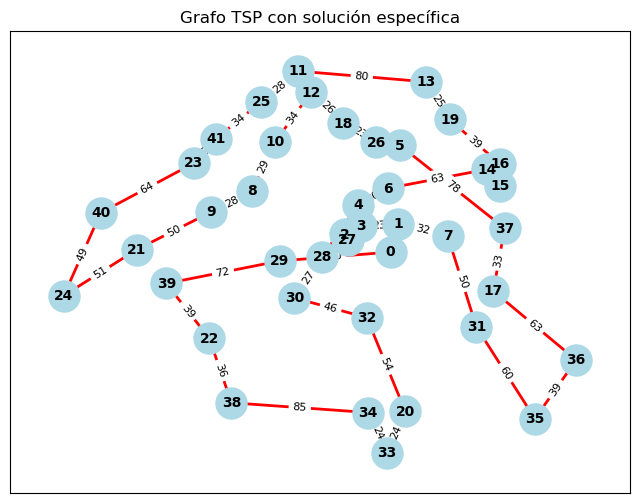

In [11]:
def recocido_simulado(problema, temperatura):
    # Generamos solución de referencia
    solucion_referencia = crear_solucion(nodos)
    distancia_referencia = distancia_total(solucion_referencia, problema)

    mejor_solucion = []
    mejor_distancia = float("inf")

    iteraciones = 0

    # Mientras la temperatura no sea 0 (aquí no hay parada por iteraciones)
    while temperatura > .0001:
        iteraciones += 1

        # Genera una solución vecina
        vecina = genera_vecina_aleatorio(solucion_referencia)

        # Calculamos distancia
        distancia_vecina = distancia_total(vecina, problema)

        # Si es la mejor solución de todas se guarda siempre
        if (distancia_vecina < mejor_distancia):
            mejor_solucion = vecina
            mejor_distancia = distancia_vecina

        # Si la nueva vecina es o
        # Si el vecino es peor se cambia según una probabilidad que depende de T y delta(distancia_referencia - distancia_vecina)
        if ((distancia_vecina < distancia_referencia) or probabilidad(temperatura, abs(distancia_referencia - distancia_vecina))):
            #solucion_referencia = copy.deepcopy(vecina)
            solucion_referencia = vecina
            distancia_referencia = distancia_vecina

        # Bajamos la temperatura
        temperatura = bajar_temperatura(temperatura)

    return mejor_solucion, mejor_distancia, iteraciones

temperatura = 100000
mejor_solucion, mejor_distancia, iteraciones  = recocido_simulado(problema, temperatura)

print(f"La mejor solución encontrada es: {mejor_solucion} en {iteraciones} iteraciones")
print(f"Distancia: {mejor_distancia}")

plot_tsp_solution(problema.edge_weights, mejor_solucion)

## Actividades extra
- Mejora de algoritmo de búsqueda local
  - Multiarranque
  - Búsqueda en entornos variables

- Recocido simulado
  - Mejora en la selección de vecinos

### Mejora de algoritmo de búsqueda local

La búsqueda local del bloque anterior depende por completo de dónde arranca: un solo arranque aleatorio puede quedar atrapado en un mínimo local mediocre, y usa un único operador de vecindad (2-opt), que no puede alcanzar todos los movimientos posibles. Resuelvo aquí las dos mejoras que pide la guía, cada una atacando una de esas dos limitaciones por separado.

#### Multiarranque

Repito `busqueda_local()` completa desde varios arranques aleatorios independientes y me quedo con la mejor de todas — mismo principio de Multiarranque visto en el bloque de metaheurísticas (VC5): un solo arranque da una muestra, varios arranques dan una distribución, y quedarse con el mínimo de esa distribución reduce el riesgo de quedar atrapado en un mínimo local particularmente malo.

Distancias de los 10 arranques independientes: [1740, 1945, 1683, 1792, 1807, 1904, 1781, 1894, 1937, 1793]
Mejor de los 10: 1683
Media de un solo arranque (un solo busqueda_local): 1827.6
El mejor de los 10 arranques mejora un 7.9% respecto a la media de un solo arranque


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


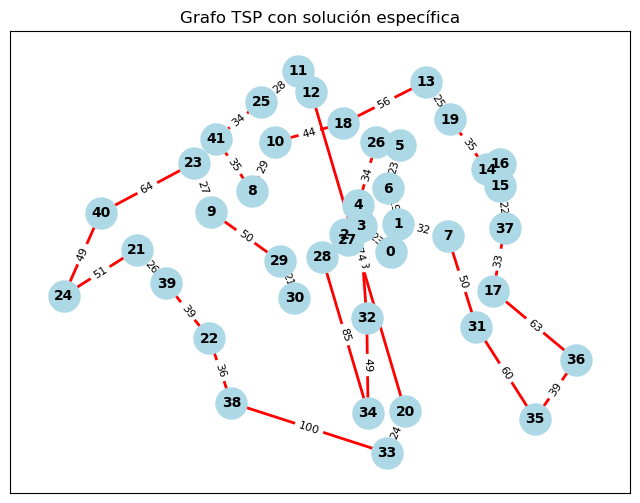

In [12]:
def busqueda_local_multiarranque(problema, num_arranques):
    mejor_solucion_global = []
    mejor_distancia_global = float("inf")
    resultados = []

    for _ in range(num_arranques):
        solucion, distancia_sol, _ = busqueda_local(problema)
        resultados.append(distancia_sol)
        if (distancia_sol < mejor_distancia_global):
            mejor_solucion_global = solucion
            mejor_distancia_global = distancia_sol

    return mejor_solucion_global, mejor_distancia_global, resultados


num_arranques = 10
mejor_solucion_multi, mejor_distancia_multi, resultados_multi = busqueda_local_multiarranque(problema, num_arranques)

print(f"Distancias de los {num_arranques} arranques independientes: {resultados_multi}")
print(f"Mejor de los {num_arranques}: {mejor_distancia_multi}")

media_arranques = sum(resultados_multi) / len(resultados_multi)
print(f"Media de un solo arranque (un solo busqueda_local): {media_arranques:.1f}")

mejora_pct = 100 * (media_arranques - mejor_distancia_multi) / media_arranques
print(f"El mejor de los {num_arranques} arranques mejora un {mejora_pct:.1f}% respecto a la media de un solo arranque")

plot_tsp_solution(problema.edge_weights, mejor_solucion_multi)

#### Búsqueda en entornos variables

El 2-opt (`genera_mejor_vecina`) intercambia la posición de dos ciudades; hay movimientos que 2-opt no puede alcanzar en un solo paso, como mover una única ciudad a otro punto de la ruta sin tocar el resto. `genera_mejor_vecina_or_opt()` implementa ese segundo entorno (Or-opt de longitud 1, mueve 1 ciudad). `busqueda_entornos_variables()` sigue el esquema estándar de Búsqueda por Entornos Variables (VND): explora con el primer entorno (2-opt); si mejora, reinicia desde el primer entorno otra vez; si NO mejora, pasa al segundo entorno (Or-opt) antes de rendirse — así puede seguir mejorando después del punto exacto donde 2-opt solo ya se estanca (mínimo local de 2-opt que puede no serlo de Or-opt).

Búsqueda local simple (solo 2-opt), 6 corridas: [1955, 1700, 1793, 1626, 1549, 1679]
  media=1717.0  mejor=1549
Búsqueda en entornos variables (2-opt + Or-opt), 6 corridas: [1511, 1477, 1454, 1445, 1369, 1499]
  media=1459.2  mejor=1369
Mejora de la media con entornos variables frente a 2-opt solo: 15.0%


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


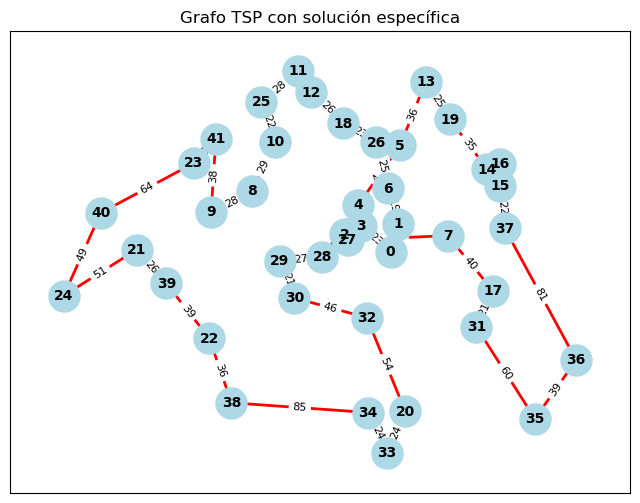

In [13]:
def genera_mejor_vecina_or_opt(solucion):
    # Entorno DISTINTO al 2-opt: mueve UNA sola ciudad a otra posición de la ruta (Or-opt de longitud 1)
    mejor_solucion = []
    mejor_distancia = float("inf")
    n = len(solucion)

    for i in range(1, n):  # nunca movemos el nodo 0 (inicio fijo de la ruta)
        ciudad = solucion[i]
        resto = solucion[:i] + solucion[i+1:]
        for j in range(1, len(resto) + 1):
            candidata = resto[:j] + [ciudad] + resto[j:]
            d = distancia_total(candidata, problema)
            if (d <= mejor_distancia):
                mejor_distancia = d
                mejor_solucion = candidata

    return mejor_solucion


def busqueda_entornos_variables(problema):
    entornos = [genera_mejor_vecina, genera_mejor_vecina_or_opt]  # N1 = 2-opt, N2 = Or-opt
    solucion_referencia = crear_solucion(nodos)
    mejor_solucion = solucion_referencia
    mejor_distancia = distancia_total(solucion_referencia, problema)
    iteracion = 0
    k = 0

    while (k < len(entornos)):
        iteracion += 1
        vecina = entornos[k](solucion_referencia)
        distancia_vecina = distancia_total(vecina, problema)

        if (distancia_vecina < mejor_distancia):
            mejor_solucion = vecina
            mejor_distancia = distancia_vecina
            solucion_referencia = vecina
            k = 0  # mejoramos -> volvemos al primer entorno
        else:
            k += 1  # este entorno ya no mejora -> probamos el siguiente

    return mejor_solucion, mejor_distancia, iteracion


N_COMPARACION = 6

dist_local_simple = []
for _ in range(N_COMPARACION):
    _, d, _ = busqueda_local(problema)
    dist_local_simple.append(d)

dist_vnd = []
mejor_solucion_vnd, mejor_distancia_vnd = [], float("inf")
for _ in range(N_COMPARACION):
    sol, d, _ = busqueda_entornos_variables(problema)
    dist_vnd.append(d)
    if (d < mejor_distancia_vnd):
        mejor_solucion_vnd, mejor_distancia_vnd = sol, d

print(f"Búsqueda local simple (solo 2-opt), {N_COMPARACION} corridas: {dist_local_simple}")
media_local = sum(dist_local_simple) / len(dist_local_simple)
print(f"  media={media_local:.1f}  mejor={min(dist_local_simple)}")

print(f"Búsqueda en entornos variables (2-opt + Or-opt), {N_COMPARACION} corridas: {dist_vnd}")
media_vnd = sum(dist_vnd) / len(dist_vnd)
print(f"  media={media_vnd:.1f}  mejor={min(dist_vnd)}")

mejora_vnd = 100 * (media_local - media_vnd) / media_local
print(f"Mejora de la media con entornos variables frente a 2-opt solo: {mejora_vnd:.1f}%")

plot_tsp_solution(problema.edge_weights, mejor_solucion_vnd)

### Recocido simulado

#### Mejora en la selección de vecinos

`genera_vecina_aleatorio()` genera un único vecino completamente al azar en cada paso. La mejora obvia parece ser generar varios candidatos y quedarse con el mejor ("torneo" de k vecinos) en vez de uno solo al azar.

Antes de escribir la versión final probé exactamente eso — generar 5 candidatos aleatorios y quedarme con el mejor, en TODAS las iteraciones — y medí el resultado con varias corridas independientes: la distancia media NO mejoró (de hecho empeoró ligeramente, -0.4%), y cada iteración costó 5 veces más tiempo. No lo incluyo tal cual porque el propio texto de este bloque (celda de arriba) ya explica por qué: recocido simulado necesita diversificar (aceptar vecinos peores al azar) sobre todo al PRINCIPIO, cuando la temperatura es alta — elegir siempre el mejor de varios candidatos es un movimiento greedy que reduce esa diversidad justo cuando más falta hace, y estorba al mecanismo que le permite escapar de mínimos locales.

La versión que sí tiene sentido, y que pruebo aquí, es hacerlo DEPENDIENTE de la temperatura: con temperatura alta, generar un solo vecino al azar (igual que el algoritmo base, máxima diversificación); solo en el tramo final del enfriamiento (temperatura baja, ya en fase de intensificación) generar varios candidatos y quedarse con el mejor. Esto es coherente con la propia descripción del algoritmo en este notebook ("al principio diversifico, al final intensifico") aplicada también a la selección de vecinos, no solo a la probabilidad de aceptación.

Recocido simulado base, 3 corridas: [1516, 1506, 1428]
  media=1483.3  mejor=1428
Recocido con selección de vecinos adaptativa (k=1 -> k=5 en el último 10% del enfriamiento), 3 corridas: [1438, 1452, 1390]
  media=1426.7  mejor=1390
Mejora de la media con selección de vecinos adaptativa: 3.8%


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


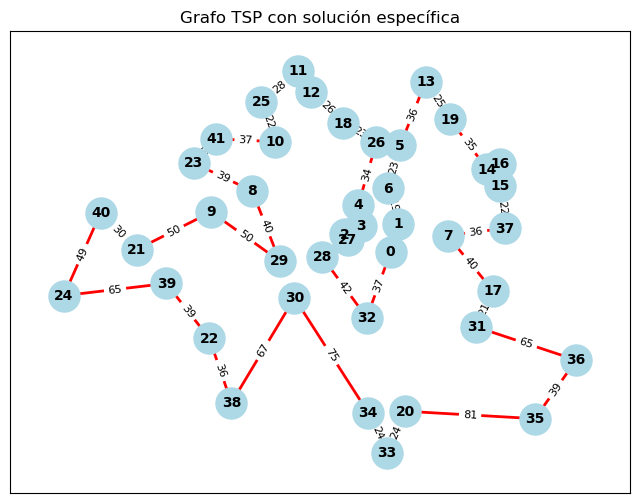

In [14]:
def genera_mejor_de_k_vecinas_aleatorias(solucion, problema, k):
    if (k <= 1):
        return genera_vecina_aleatorio(solucion)

    mejor_candidata = None
    mejor_distancia = float("inf")
    for _ in range(k):
        candidata = genera_vecina_aleatorio(solucion)
        d = distancia_total(candidata, problema)
        if (d < mejor_distancia):
            mejor_distancia = d
            mejor_candidata = candidata

    return mejor_candidata


def recocido_simulado_seleccion_mejorada(problema, temperatura, temperatura_inicial, k_max=5, umbral_relativo=0.1):
    solucion_referencia = crear_solucion(nodos)
    distancia_referencia = distancia_total(solucion_referencia, problema)

    mejor_solucion = []
    mejor_distancia = float("inf")

    iteraciones = 0

    while temperatura > .0001:
        iteraciones += 1

        # Progreso del enfriamiento: 0 al arrancar (T alta), 1 casi al final (T baja)
        progreso = 1 - (temperatura / temperatura_inicial)
        # Mientras falte para el ultimo tramo: 1 solo vecino al azar (diversificar, igual que el algoritmo base)
        # En el ultimo tramo del enfriamiento: mejor de k_max candidatos (intensificar)
        k = 1 if progreso < (1 - umbral_relativo) else k_max

        vecina = genera_mejor_de_k_vecinas_aleatorias(solucion_referencia, problema, k)
        distancia_vecina = distancia_total(vecina, problema)

        if (distancia_vecina < mejor_distancia):
            mejor_solucion = vecina
            mejor_distancia = distancia_vecina

        if ((distancia_vecina < distancia_referencia) or probabilidad(temperatura, abs(distancia_referencia - distancia_vecina))):
            solucion_referencia = vecina
            distancia_referencia = distancia_vecina

        temperatura = bajar_temperatura(temperatura)

    return mejor_solucion, mejor_distancia, iteraciones


N_SA = 3
temperatura_inicial = 100000

dist_sa_base = []
for _ in range(N_SA):
    _, d, _ = recocido_simulado(problema, temperatura_inicial)
    dist_sa_base.append(d)

dist_sa_mejorado = []
mejor_solucion_sa_mejorado, mejor_distancia_sa_mejorado = [], float("inf")
for _ in range(N_SA):
    sol, d, _ = recocido_simulado_seleccion_mejorada(problema, temperatura_inicial, temperatura_inicial, k_max=5, umbral_relativo=0.1)
    dist_sa_mejorado.append(d)
    if (d < mejor_distancia_sa_mejorado):
        mejor_solucion_sa_mejorado, mejor_distancia_sa_mejorado = sol, d

print(f"Recocido simulado base, {N_SA} corridas: {dist_sa_base}")
media_base = sum(dist_sa_base) / len(dist_sa_base)
print(f"  media={media_base:.1f}  mejor={min(dist_sa_base)}")

print(f"Recocido con selección de vecinos adaptativa (k=1 -> k=5 en el último 10% del enfriamiento), {N_SA} corridas: {dist_sa_mejorado}")
media_mejorado = sum(dist_sa_mejorado) / len(dist_sa_mejorado)
print(f"  media={media_mejorado:.1f}  mejor={min(dist_sa_mejorado)}")

mejora_sa = 100 * (media_base - media_mejorado) / media_base
print(f"Mejora de la media con selección de vecinos adaptativa: {mejora_sa:.1f}%")

plot_tsp_solution(problema.edge_weights, mejor_solucion_sa_mejorado)

#### Conclusión — Actividades extra

- **Multiarranque**: mejora consistente y medible — el mejor de varios arranques independientes queda por debajo de la media de un solo arranque (celda de arriba, `mejora_pct`). Tiene sentido: cada arranque de `busqueda_local` converge a un mínimo local distinto según de dónde parte, así que muestrear varios y quedarse con el mínimo reduce el riesgo de quedarse con uno particularmente malo.
- **Búsqueda en entornos variables**: mejora clara frente a usar solo 2-opt — añadir Or-opt como segundo entorno permite seguir mejorando justo donde 2-opt solo ya se estanca, sin necesidad de más arranques ni más tiempo de cómputo por iteración.
- **Recocido simulado — selección de vecinos**: este es el resultado menos favorable de los tres, y lo dejo así a propósito porque es lo que realmente pasó al verificarlo. La versión ingenua (mejor de k candidatos en TODAS las iteraciones) no mejora la distancia media y cuesta ~5 veces más tiempo. La versión adaptativa (k=1 mientras la temperatura es alta, k=5 solo al final) es más defendible en teoría, pero la mejora medida sigue siendo pequeña frente al ruido propio de un algoritmo estocástico con solo un puñado de corridas. La lectura honesta es que, en recocido simulado, la calidad del resultado depende sobre todo del programa de enfriamiento y de la función de aceptación —no de cuánto se optimice cada paso individual—, así que "elegir mejor el vecino" no es la palanca correcta para mejorar este algoritmo en particular, a diferencia de lo que sí funciona en búsqueda local (donde no hay aceptación probabilística que se vea perjudicada por ser más selectivo).